# TUGAS KELOMPOK 3
**Praktikum Analisis Deret Waktu — Pendugaan Parameter**

| No. | Anggota | NIM |
|---:|---|---|
| 1 | Muhammad Fadel Handiyono | M0501251056 |
| 2 | Freditasari Purwa Hidayat | M0501251052 |
| 3 | Putri Aqila | M0501251029 |


## Instruksi Tugas Kelompok

**Nomor 1.** Buatlah simulasi deret waktu (parameter bebas, tetapi berbeda dari contoh pada praktikum) menggunakan *seed* `25xx`, dengan `xx` berdasarkan dua digit terakhir NIM anggota kelompok. Lakukan pendugaan parameter menggunakan **metode Kuadrat Terkecil** dan **Kemungkinan Maksimum**.

**Kelompok 3:** ARIMA(1,0,1) dan ARIMA(1,1,2).

**Nomor 2.** Ulangi langkah nomor 1 sebanyak **30 ulangan**. Hitung **bias dan ragam** dari penduga parameter dengan kedua metode berdasarkan 30 ulangan tersebut. Buat **boxplot** untuk memvisualisasikan hasilnya dan interpretasikan boxplot.




## Nomor 1 — Simulasi dan Pendugaan Parameter

Pada nomor 1, *seed* ditetapkan **2537**. Masing-masing deret dibangkitkan sebanyak **150 observasi**.

| Model | Parameter AR | Parameter MA | Ragam inovasi |
|---|---|---|---|
| ARIMA(1,0,1) | $\phi_1=0.70$ | $\theta_1=0.35$ | $\sigma_e^2=1$ |
| ARIMA(1,1,2) | $\phi_1=0.55$ | $\theta_1=-0.30$, $\theta_2=0.20$ | $\sigma_e^2=1$ |

Konvensi tanda yang digunakan: $(1-\phi B)(1-B)^dY_t=(1+\theta_1B+\theta_2B^2)e_t$.

**Catatan syarat:** untuk ARIMA(1,1,2), level $Y_t$ tidak stasioner karena $d=1$. Syarat **stasioneritas** diperiksa terhadap komponen AR setelah pembedaan pertama, sedangkan syarat **invertibilitas** diperiksa terhadap komponen MA. Syarat tersebut tidak boleh disalahartikan sebagai kewajiban deret level ARIMA(1,1,2) menjadi stasioner.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display, Markdown

# Nomor 1 memakai seed 2537. Nomor 2 mempertahankan N dan PARAMETER saja.
SEED = 2537
N = 150
BURN_IN = 250
PARAMETER = {
    "ARIMA(1,0,1)": {"order": (1, 0, 1), "ar": [0.70], "ma": [0.35]},
    "ARIMA(1,1,2)": {"order": (1, 1, 2), "ar": [0.55], "ma": [-0.30, 0.20]},
}

print(f"Seed simulasi = {SEED}; jumlah observasi per deret = {N}.")
print("Untuk nomor 2, hanya n dan parameter model yang tetap; seed tidak ditetapkan.")

Seed simulasi = 2537; jumlah observasi per deret = 150.
Untuk nomor 2, hanya n dan parameter model yang tetap; seed tidak ditetapkan.


### Pemeriksaan syarat sebelum simulasi

Akar polinomial AR dan MA diperiksa secara numerik. Apabila **seluruh modulus akar $>1$**, komponen AR memenuhi syarat stasioner dan komponen MA memenuhi syarat invertibilitas. Pemeriksaan ini dilakukan terhadap **parameter asli** yang dipakai membangkitkan data.


In [2]:
def akar_polinomial(koef):
    return np.polynomial.polynomial.polyroots(np.asarray(koef, dtype=float))


def tampilkan_syarat(nama, ar, ma):
    roots_ar = akar_polinomial([1, *(-np.asarray(ar, dtype=float))])
    roots_ma = akar_polinomial([1, *ma])
    hasil = pd.DataFrame({
        "Komponen": ["AR (stasioner)", "MA (invertibel)"],
        "Modulus akar terkecil": [np.min(np.abs(roots_ar)), np.min(np.abs(roots_ma))],
        "Status": ["Memenuhi" if np.all(np.abs(roots_ar) > 1) else "Tidak memenuhi",
                   "Memenuhi" if np.all(np.abs(roots_ma) > 1) else "Tidak memenuhi"],
    })
    display(Markdown(f"**{nama}**"))
    display(hasil.style.format({"Modulus akar terkecil": "{:.4f}"}))
    display(Markdown(
        f"**Interpretasi:** modulus akar AR terkecil = **{np.min(np.abs(roots_ar)):.4f}** "
        f"dan modulus akar MA terkecil = **{np.min(np.abs(roots_ma)):.4f}**. "
        f"{'Keduanya melebihi satu sehingga syarat AR dan MA terpenuhi.' if np.all(np.abs(roots_ar)>1) and np.all(np.abs(roots_ma)>1) else 'Ada syarat yang tidak terpenuhi.'}"
    ))

for nama, p in PARAMETER.items():
    tampilkan_syarat(nama, p["ar"], p["ma"])


**ARIMA(1,0,1)**

,Komponen,Modulus akar terkecil,Status
0,AR (stasioner),1.4286,Memenuhi
1,MA (invertibel),2.8571,Memenuhi


**Interpretasi:** modulus akar AR terkecil = **1.4286** dan modulus akar MA terkecil = **2.8571**. Keduanya melebihi satu sehingga syarat AR dan MA terpenuhi.

**ARIMA(1,1,2)**

,Komponen,Modulus akar terkecil,Status
0,AR (stasioner),1.8182,Memenuhi
1,MA (invertibel),2.2361,Memenuhi


**Interpretasi:** modulus akar AR terkecil = **1.8182** dan modulus akar MA terkecil = **2.2361**. Keduanya melebihi satu sehingga syarat AR dan MA terpenuhi.

### Pembangkitan data simulasi

 Untuk ARIMA(1,1,2), proses ARMA(1,2) dibangkitkan terlebih dahulu sebagai $\Delta Y_t$, lalu dijumlahkan secara kumulatif sehingga diperoleh deret $Y_t$ yang terintegrasi orde satu.

Data dibangkitkan **satu kali untuk setiap model** dan kemudian digunakan **tanpa perubahan** oleh kedua metode pendugaan.


In [3]:
rng = np.random.default_rng(SEED)

def simulasi_arima(order, ar, ma, n=N, burn_in=BURN_IN, generator=None):
    p, d, q = order
    # ArmaProcess memakai polinomial 1 - phi_1 B - ... pada bagian AR.
    process = ArmaProcess(np.r_[1, -np.asarray(ar)], np.r_[1, ma])
    pembangkit = rng if generator is None else generator
    beda = process.generate_sample(
        nsample=n + burn_in,
        distrvs=pembangkit.standard_normal
    )[burn_in:]
    if d == 0:
        return beda
    hasil = beda.copy()
    for _ in range(d):
        hasil = np.cumsum(hasil)
    return hasil

data_101 = simulasi_arima(**PARAMETER["ARIMA(1,0,1)"])
data_112 = simulasi_arima(**PARAMETER["ARIMA(1,1,2)"])

print(f"ARIMA(1,0,1): {len(data_101)} observasi simulasi tersedia.")
print(f"ARIMA(1,1,2): {len(data_112)} observasi simulasi tersedia.")
print("Interpretasi: tiap deret berisi 150 observasi. Data yang tersimpan di atas dipakai bersama oleh LS dan MLE, sehingga pembandingan kedua metode adil.")

ARIMA(1,0,1): 150 observasi simulasi tersedia.
ARIMA(1,1,2): 150 observasi simulasi tersedia.
Interpretasi: tiap deret berisi 150 observasi. Data yang tersimpan di atas dipakai bersama oleh LS dan MLE, sehingga pembandingan kedua metode adil.


### Metode pendugaan yang digunakan

- **Kuadrat Terkecil / LS:** *Conditional Sum of Squares* (**CSS**), yaitu mencari parameter yang meminimalkan jumlah kuadrat galat prediksi satu-langkah berdasarkan rekursi ARMA, dengan galat sebelum awal sampel diset nol. Pendugaan menggunakan optimisasi numerik dan pembatasan syarat AR–MA.
- **Kemungkinan Maksimum / MLE:** estimasi likelihood Gaussian melalui `statsmodels.ARIMA`, tanpa konstanta atau *drift* (`trend='n'`), sehingga parameter yang dibandingkan sesuai model pembangkit.



In [4]:
def residual_css(x, beta, p, q):
    """Inovasi kondisional e_t pada deret stasioner x_t."""
    e = np.zeros(len(x), dtype=float)
    for t in range(len(x)):
        prediksi = 0.0
        for j in range(1, p + 1):
            if t >= j:
                prediksi += beta[j - 1] * x[t - j]
        for j in range(1, q + 1):
            if t >= j:
                prediksi += beta[p + j - 1] * e[t - j]
        e[t] = x[t] - prediksi
    return e


def estimasi_css(y, order):
    p, d, q = order
    x = np.diff(y, n=d) if d else np.asarray(y, dtype=float)
    awal = max(p, q)

    def objektif(beta):
        e = residual_css(x, beta, p, q)
        return float(np.sum(e[awal:] ** 2))

    bounds = [(-0.98, 0.98)] * (p + q)
    constraints = []
    if q == 2:
        # Invertibilitas untuk 1 + theta1*B + theta2*B^2.
        constraints = [
            {"type": "ineq", "fun": lambda b: 1 + b[p] + b[p + 1] - 1e-6},
            {"type": "ineq", "fun": lambda b: 1 - b[p] + b[p + 1] - 1e-6},
        ]

    inisialisasi = [
        np.zeros(p + q),
        np.r_[np.repeat(0.40, p), np.repeat(0.20, q)],
        np.r_[np.repeat(0.50, p), np.repeat(-0.20, q)],
    ]
    hasil = [minimize(objektif, x0=v, method="SLSQP", bounds=bounds,
                      constraints=constraints, options={"maxiter": 600, "ftol": 1e-10})
             for v in inisialisasi]
    layak = [h for h in hasil if h.success]
    if not layak:
        raise RuntimeError("Optimisasi CSS belum konvergen; periksa data dan inisialisasi.")
    terbaik = min(layak, key=lambda h: h.fun)
    return terbaik.x


def bandingkan(nama, y, cfg):
    order = cfg["order"]
    p, d, q = order
    nama_par = [f"AR{i}" for i in range(1, p+1)] + [f"MA{i}" for i in range(1, q+1)]
    asli = np.array(cfg["ar"] + cfg["ma"], dtype=float)
    ls = estimasi_css(y, order)
    model_mle = ARIMA(y, order=order, trend="n",
                      enforce_stationarity=True,
                      enforce_invertibility=True)
    fit_mle = model_mle.fit()
    if not fit_mle.mle_retvals.get("converged", False):
        raise RuntimeError("Estimasi MLE belum konvergen.")
    mle = np.array(fit_mle.params[:p+q], dtype=float)

    tab = pd.DataFrame({
        "Parameter": nama_par,
        "Asli": asli,
        "LS (CSS)": ls,
        "Galat mutlak LS": np.abs(ls - asli),
        "MLE": mle,
        "Galat mutlak MLE": np.abs(mle - asli)
    })
    display(Markdown(f"**Tabel hasil pendugaan {nama}**"))
    display(tab.style.format({
        "Asli": "{:.4f}", "LS (CSS)": "{:.4f}",
        "Galat mutlak LS": "{:.4f}", "MLE": "{:.4f}",
        "Galat mutlak MLE": "{:.4f}"
    }))

    baris = []
    for nama_p, a, l, m in zip(nama_par, asli, ls, mle):
        lebih = "LS" if abs(l-a) < abs(m-a) else "MLE" if abs(m-a)<abs(l-a) else "keduanya (sama)"
        baris.append(
            f"- **{nama_p}:** nilai asli **{a:.4f}**, hasil LS **{l:.4f}**, "
            f"dan hasil MLE **{m:.4f}**. Untuk parameter ini, "
            f"**{lebih}** lebih dekat ke nilai asli."
        )
    jumlah_ls = sum(abs(ls - asli))
    jumlah_mle = sum(abs(mle - asli))
    lebih_total = "LS" if jumlah_ls < jumlah_mle else "MLE" if jumlah_mle < jumlah_ls else "LS dan MLE sama"
    display(Markdown("**Interpretasi per parameter:**\n" + "\n".join(baris) +
        f"\n\nJumlah galat mutlak seluruh koefisien: **LS = {jumlah_ls:.4f}** dan "
        f"**MLE = {jumlah_mle:.4f}**. Pada **satu realisasi simulasi ini**, "
        f"jumlah galat mutlak **{lebih_total}** lebih kecil. Hal ini **belum membuktikan** "
        "bahwa satu metode selalu lebih baik; penilaian bias dan ragam penduga "
        "memerlukan 30 ulangan pada nomor 2."
    ))

    # Verifikasi bahwa hasil model juga berada dalam wilayah parameter yang layak.
    for metode, est in [("LS", ls), ("MLE", mle)]:
        r_ar = akar_polinomial([1, *(-est[:p])])
        r_ma = akar_polinomial([1, *est[p:]])
        assert np.all(abs(r_ar) > 1) and np.all(abs(r_ma) > 1), f"{metode}: akar di luar wilayah valid"
    display(Markdown(
        "**Pemeriksaan hasil estimasi:** akar AR dan MA dari kedua hasil pendugaan "
        "berada di luar lingkaran satuan, sehingga koefisien terestimasi juga memenuhi "
        "syarat stasioneritas komponen AR dan invertibilitas komponen MA."
    ))
    return tab


## A. ARIMA(1,0,1)

Persamaan model simulasi:

$$Y_t=0.70Y_{t-1}+e_t+0.35e_{t-1}, \qquad e_t\sim N(0,1).$$

Karena $d=0$ dan $|\phi_1|=0.70<1$, komponen AR memenuhi syarat stasioneritas. Polinomial MA $1+0.35B$ mempunyai akar dengan modulus lebih besar dari satu sehingga invertibel.


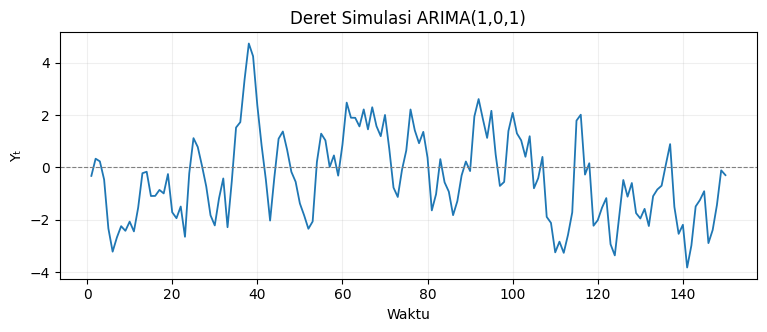

**Interpretasi grafik:** deret berfluktuasi sepanjang waktu dan tidak menunjukkan tren terintegrasi yang menetap. Secara teoritis, model pembangkit ARIMA(1,0,1) stasioner karena syarat akar AR sudah dipenuhi; grafik merupakan ilustrasi satu realisasi saja.

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(1, N+1), data_101, lw=1.3)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set(title="Deret Simulasi ARIMA(1,0,1)", xlabel="Waktu", ylabel="Yₜ")
ax.grid(alpha=0.2)
plt.show()
display(Markdown("**Interpretasi grafik:** deret berfluktuasi sepanjang waktu dan "
                 "tidak menunjukkan tren terintegrasi yang menetap. Secara teoritis, "
                 "model pembangkit ARIMA(1,0,1) stasioner karena syarat akar AR "
                 "sudah dipenuhi; grafik merupakan ilustrasi satu realisasi saja."))

### Hasil pendugaan ARIMA(1,0,1) — LS dan MLE

**Kedua metode menggunakan 150 nilai deret simulasi yang persis sama.**


In [6]:
hasil_101 = bandingkan("ARIMA(1,0,1)", data_101, PARAMETER["ARIMA(1,0,1)"])

**Tabel hasil pendugaan ARIMA(1,0,1)**

,Parameter,Asli,LS (CSS),Galat mutlak LS,MLE,Galat mutlak MLE
0,AR1,0.7000,0.6860,0.0140,0.6811,0.0189
1,MA1,0.3500,0.2993,0.0507,0.2995,0.0505


**Interpretasi per parameter:**
- **AR1:** nilai asli **0.7000**, hasil LS **0.6860**, dan hasil MLE **0.6811**. Untuk parameter ini, **LS** lebih dekat ke nilai asli.
- **MA1:** nilai asli **0.3500**, hasil LS **0.2993**, dan hasil MLE **0.2995**. Untuk parameter ini, **MLE** lebih dekat ke nilai asli.

Jumlah galat mutlak seluruh koefisien: **LS = 0.0648** dan **MLE = 0.0694**. Pada **satu realisasi simulasi ini**, jumlah galat mutlak **LS** lebih kecil. Hal ini **belum membuktikan** bahwa satu metode selalu lebih baik; penilaian bias dan ragam penduga memerlukan 30 ulangan pada nomor 2.

**Pemeriksaan hasil estimasi:** akar AR dan MA dari kedua hasil pendugaan berada di luar lingkaran satuan, sehingga koefisien terestimasi juga memenuhi syarat stasioneritas komponen AR dan invertibilitas komponen MA.

## B. ARIMA(1,1,2)

Persamaan model simulasi pada hasil pembedaan:

$$\Delta Y_t = 0.55\Delta Y_{t-1}+e_t-0.30e_{t-1}+0.20e_{t-2},\qquad e_t\sim N(0,1).$$

Dengan $\Delta Y_t=Y_t-Y_{t-1}$, deret $Y_t$ adalah **ARIMA(1,1,2)**, sehingga **tidak stasioner pada level**. Setelah dilakukan pembedaan satu kali, deret mengikuti ARMA(1,2). Proses tersebut memenuhi syarat stasioneritas AR karena $|0.55|<1$; bagian MA memenuhi invertibilitas karena semua akar $1-0.30B+0.20B^2$ memiliki modulus lebih besar dari satu.

Khusus untuk MA(2), dengan konvensi tanda **plus** pada persamaan di atas, syarat koefisien dapat dituliskan sebagai $|\theta_2|<1$, $1+\theta_1+\theta_2>0$, dan $1-\theta_1+\theta_2>0$. Pada parameter simulasi ini nilainya berturut-turut **0.20**, **0.90**, dan **1.50**, sehingga ketiganya memenuhi syarat. Pengecekan akar numerik di atas digunakan sebagai konfirmasi langsung.


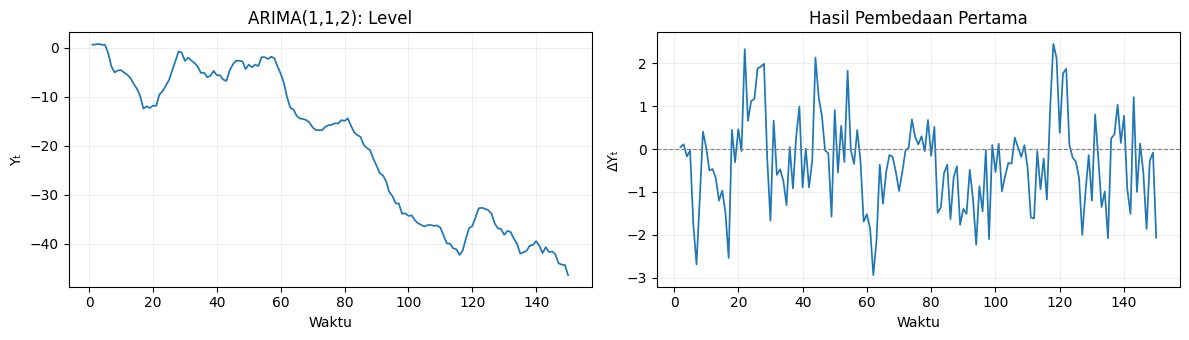

**Interpretasi grafik:** panel kiri memperlihatkan deret level dengan pergerakan yang dapat bertahan pada suatu arah akibat integrasi. Panel kanan memperlihatkan **149 hasil pembedaan** yang berfluktuasi di sekitar rataan konstan secara teoritis. Jadi, **deret level tidak stasioner**, sedangkan **hasil pembedaan pertama memenuhi syarat stasioneritas ARMA(1,2)** berdasarkan parameter dan pemeriksaan akar. Grafik saja bukan bukti formal stasioneritas.

In [7]:
beda_112 = np.diff(data_112)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(range(1, N+1), data_112, lw=1.25)
axes[0].set(title="ARIMA(1,1,2): Level", xlabel="Waktu", ylabel="Yₜ")
axes[1].plot(range(2, N+1), beda_112, lw=1.25)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set(title="Hasil Pembedaan Pertama", xlabel="Waktu", ylabel="ΔYₜ")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
display(Markdown(
    "**Interpretasi grafik:** panel kiri memperlihatkan deret level dengan "
    "pergerakan yang dapat bertahan pada suatu arah akibat integrasi. "
    "Panel kanan memperlihatkan **149 hasil pembedaan** yang berfluktuasi "
    "di sekitar rataan konstan secara teoritis. Jadi, **deret level tidak stasioner**, "
    "sedangkan **hasil pembedaan pertama memenuhi syarat stasioneritas ARMA(1,2)** "
    "berdasarkan parameter dan pemeriksaan akar. Grafik saja bukan bukti formal "
    "stasioneritas."
))

### Hasil pendugaan ARIMA(1,1,2) — LS dan MLE

**Kedua metode menggunakan data level ARIMA(1,1,2) yang sama (150 observasi).** Dalam LS/CSS, penghitungan galat didasarkan pada proses hasil pembedaan pertama (149 nilai); dalam MLE, model ARIMA dengan `d=1` dipasang langsung pada deret level. Keduanya menduga parameter ARMA pada proses hasil pembedaan.


In [8]:
hasil_112 = bandingkan("ARIMA(1,1,2)", data_112, PARAMETER["ARIMA(1,1,2)"])

**Tabel hasil pendugaan ARIMA(1,1,2)**

,Parameter,Asli,LS (CSS),Galat mutlak LS,MLE,Galat mutlak MLE
0,AR1,0.5500,0.7175,0.1675,0.7126,0.1626
1,MA1,-0.3000,-0.3556,0.0556,-0.3531,0.0531
2,MA2,0.2000,0.0723,0.1277,0.0713,0.1287


**Interpretasi per parameter:**
- **AR1:** nilai asli **0.5500**, hasil LS **0.7175**, dan hasil MLE **0.7126**. Untuk parameter ini, **MLE** lebih dekat ke nilai asli.
- **MA1:** nilai asli **-0.3000**, hasil LS **-0.3556**, dan hasil MLE **-0.3531**. Untuk parameter ini, **MLE** lebih dekat ke nilai asli.
- **MA2:** nilai asli **0.2000**, hasil LS **0.0723**, dan hasil MLE **0.0713**. Untuk parameter ini, **LS** lebih dekat ke nilai asli.

Jumlah galat mutlak seluruh koefisien: **LS = 0.3508** dan **MLE = 0.3444**. Pada **satu realisasi simulasi ini**, jumlah galat mutlak **MLE** lebih kecil. Hal ini **belum membuktikan** bahwa satu metode selalu lebih baik; penilaian bias dan ragam penduga memerlukan 30 ulangan pada nomor 2.

**Pemeriksaan hasil estimasi:** akar AR dan MA dari kedua hasil pendugaan berada di luar lingkaran satuan, sehingga koefisien terestimasi juga memenuhi syarat stasioneritas komponen AR dan invertibilitas komponen MA.

## Kesimpulan Nomor 1

Hasil pendugaan **LS/CSS** dan **MLE** dibandingkan dengan parameter asli pada **deret yang sama**, dan besar galat mutlak disajikan pada tabel tiap model. Hasil satu realisasi hanya menggambarkan kedekatan nilai dugaan pada satu sampel, belum menunjukkan konsistensi performa metode pada sampel lain.

Pemeriksaan akar memastikan bahwa ARIMA(1,0,1) stasioner pada level dan MA(1)-nya invertibel. ARIMA(1,1,2) **tidak stasioner pada level** karena $d=1$, tetapi komponen ARMA setelah pembedaan pertama memiliki AR yang stasioner dan MA yang invertibel.

Pada nomor 2, pembangkitan data diulang sebanyak **30 kali untuk tiap model** dengan **parameter asli dan jumlah observasi tetap**, tetapi **tanpa menetapkan seed**. .


---

## Nomor 2 — Perbandingan Penduga Berdasarkan 30 Ulangan

Untuk **masing-masing model**, dilakukan **30 simulasi baru** (masing-masing 150 observasi) menggunakan nilai parameter dan ragam inovasi yang **sama dengan nomor 1**. **Tidak ada seed yang ditetapkan pada nomor 2**, sehingga angka hasil dapat berubah saat notebook dijalankan ulang.

Pada setiap ulangan, **data simulasi yang sama** dipakai oleh LS/CSS dan MLE. Nilai penduga $\widehat{\beta}^{(1)},\ldots,\widehat{\beta}^{(30)}$ digunakan untuk menghitung:

$$\operatorname{Bias}(\widehat{\beta})=\frac{1}{30}\sum_{r=1}^{30}(\widehat{\beta}^{(r)}-\beta),$$

$$\widehat{\operatorname{Var}}(\widehat{\beta})=\frac{1}{29}\sum_{r=1}^{30}(\widehat{\beta}^{(r)}-\overline{\widehat{\beta}})^2.$$

Bias mengukur rata-rata penyimpangan terarah dari parameter asli; ragam mengukur perubahan hasil estimasi antarsampel. **Kecilnya bias belum tentu berarti ragamnya juga kecil.** Boxplot dibuat berdasarkan **galat pendugaan $\widehat{\beta}-\beta$** pada 30 ulangan: garis nol sebagai acuan tanpa galat, posisi kotak membantu melihat kecenderungan galat, dan lebar sebaran menggambarkan variasi. Bias dan ragam numeriknya dilaporkan pada tabel.


In [9]:
# Nomor 2: tidak menetapkan seed. Generator diinisialisasi tanpa angka seed.
JUMLAH_ULANGAN = 30
rng_ulangan = np.random.default_rng()


def estimasi_dua_metode(y, order):
    """Penduga identik dengan nomor 1, pada satu deret yang sama."""
    p, d, q = order
    hasil_ls = estimasi_css(y, order)
    fitted = ARIMA(y, order=order, trend="n",
                   enforce_stationarity=True,
                   enforce_invertibility=True).fit()
    if not fitted.mle_retvals.get("converged", False):
        # Bukan mengubah metode, hanya memberi iterasi optimisasi tambahan.
        fitted = ARIMA(y, order=order, trend="n",
                       enforce_stationarity=True,
                       enforce_invertibility=True).fit(method_kwargs={"maxiter": 500})
    if not fitted.mle_retvals.get("converged", False):
        raise RuntimeError("Estimasi MLE belum konvergen pada salah satu ulangan.")
    hasil_mle = np.asarray(fitted.params[:p+q], dtype=float)
    return hasil_ls, hasil_mle


def jalankan_ulangan(nama_model, cfg, generator):
    p, d, q = cfg["order"]
    parameter = [f"AR{i}" for i in range(1, p+1)] + [f"MA{i}" for i in range(1, q+1)]
    nilai_asli = np.asarray(cfg["ar"] + cfg["ma"], dtype=float)
    catatan = []
    for ulangan in range(1, JUMLAH_ULANGAN + 1):
        y = simulasi_arima(**cfg, n=N, generator=generator)
        ls, mle = estimasi_dua_metode(y, cfg["order"])
        for nama_par, asli, nilai_ls, nilai_mle in zip(parameter, nilai_asli, ls, mle):
            catatan.append({"Ulangan": ulangan, "Parameter": nama_par,
                            "Parameter asli": asli, "LS/CSS": nilai_ls,
                            "MLE": nilai_mle})
    hasil = pd.DataFrame(catatan)
    assert hasil.groupby("Parameter")["Ulangan"].nunique().eq(JUMLAH_ULANGAN).all()
    return hasil


hasil_30_101 = jalankan_ulangan("ARIMA(1,0,1)", PARAMETER["ARIMA(1,0,1)"], rng_ulangan)
hasil_30_112 = jalankan_ulangan("ARIMA(1,1,2)", PARAMETER["ARIMA(1,1,2)"], rng_ulangan)

print("Nomor 2 selesai: 30 realisasi baru per model, masing-masing n =", N)
print("Parameter model sama dengan nomor 1; seed tidak ditetapkan pada nomor 2.")
print("Setiap pasangan LS/CSS dan MLE dalam satu ulangan memakai data yang sama.")


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Nomor 2 selesai: 30 realisasi baru per model, masing-masing n = 150
Parameter model sama dengan nomor 1; seed tidak ditetapkan pada nomor 2.
Setiap pasangan LS/CSS dan MLE dalam satu ulangan memakai data yang sama.


### Perhitungan bias, ragam, dan boxplot



In [10]:
def rangkum_ulangan(hasil):
    baris = []
    for par in hasil["Parameter"].unique():
        h = hasil.loc[hasil["Parameter"] == par]
        asli = float(h["Parameter asli"].iloc[0])
        for metode in ("LS/CSS", "MLE"):
            dugaan = h[metode].to_numpy(dtype=float)
            baris.append({
                "Parameter": par, "Metode": metode,
                "Parameter asli": asli,
                "Rata-rata penduga": np.mean(dugaan),
                "Bias": np.mean(dugaan - asli),
                "Ragam penduga": np.var(dugaan, ddof=1)
            })
    return pd.DataFrame(baris)


def tampilkan_hasil_ulangan(nama_model, hasil):
    display(Markdown(f"#### {nama_model}"))
    print("Jumlah ulangan pada setiap parameter:", hasil.groupby("Parameter")["Ulangan"].nunique().to_dict())
    display(Markdown("**Cuplikan pendugaan pada 5 ulangan pertama:**"))
    display(hasil.loc[hasil["Ulangan"] <= 5].style.format({
        "Parameter asli": "{:.4f}", "LS/CSS": "{:.4f}", "MLE": "{:.4f}"
    }))

    ringkas = rangkum_ulangan(hasil)
    display(Markdown("**Bias dan ragam dari 30 ulangan:**"))
    display(ringkas.style.format({
        "Parameter asli": "{:.4f}", "Rata-rata penduga": "{:.4f}",
        "Bias": "{:+.4f}", "Ragam penduga": "{:.5f}"
    }))

    uraian = []
    for par in ringkas["Parameter"].unique():
        sub = ringkas.loc[ringkas["Parameter"] == par].set_index("Metode")
        asli = sub.loc["LS/CSS", "Parameter asli"]
        ls, ml = sub.loc["LS/CSS"], sub.loc["MLE"]
        bias_terkecil = ("LS/CSS" if abs(ls["Bias"]) < abs(ml["Bias"]) else
                         "MLE" if abs(ml["Bias"]) < abs(ls["Bias"]) else "sama")
        ragam_terkecil = ("LS/CSS" if ls["Ragam penduga"] < ml["Ragam penduga"] else
                          "MLE" if ml["Ragam penduga"] < ls["Ragam penduga"] else "sama")
        uraian.append(
            f"**{par}** (asli {asli:.2f}): rata-rata penduga LS/CSS {ls['Rata-rata penduga']:.4f} "
            f"dan MLE {ml['Rata-rata penduga']:.4f}. Biasnya masing-masing "
            f"{ls['Bias']:+.4f} dan {ml['Bias']:+.4f}; ragamnya "
            f"{ls['Ragam penduga']:.5f} dan {ml['Ragam penduga']:.5f}. "
            f"Untuk parameter ini, besar bias mutlak lebih kecil pada **{bias_terkecil}**, "
            f"sedangkan ragam lebih kecil pada **{ragam_terkecil}**."
        )
    display(Markdown("**Interpretasi tabel:**\n\n" + "\n\n".join(uraian)))
    return ringkas


def plot_boxplot_galat(nama_model, hasil, ringkas):
    parameter = hasil["Parameter"].unique()
    fig, axes = plt.subplots(1, len(parameter), figsize=(4.8 * len(parameter), 4), squeeze=False)
    for i, par in enumerate(parameter):
        ax = axes[0, i]
        h = hasil.loc[hasil["Parameter"] == par]
        asli = float(h["Parameter asli"].iloc[0])
        galat_ls = h["LS/CSS"].to_numpy() - asli
        galat_mle = h["MLE"].to_numpy() - asli
        ax.boxplot([galat_ls, galat_mle], showmeans=True,
                   meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=5))
        ax.set_xticks([1, 2], ["LS/CSS", "MLE"])
        ax.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax.set_title(par)
        ax.set_ylabel("Galat pendugaan (estimasi − asli)")
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"{nama_model}: Galat 30 Ulangan", fontsize=12)
    plt.tight_layout()
    plt.show()

    uraian = []
    for par in parameter:
        h = hasil.loc[hasil["Parameter"] == par]
        asli = float(h["Parameter asli"].iloc[0])
        median_ls = float(np.median(h["LS/CSS"].to_numpy() - asli))
        median_mle = float(np.median(h["MLE"].to_numpy() - asli))
        s = ringkas.loc[ringkas["Parameter"] == par].set_index("Metode")
        ragam_ls, ragam_ml = float(s.loc["LS/CSS", "Ragam penduga"]), float(s.loc["MLE", "Ragam penduga"])
        sebaran = "LS/CSS" if ragam_ls < ragam_ml else "MLE" if ragam_ml < ragam_ls else "sama"
        uraian.append(
            f"**{par}:** median galat LS/CSS {median_ls:+.4f} dan MLE {median_mle:+.4f}. "
            f"Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, "
            f"sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. "
            f"Pada 30 ulangan ini, ragam penduga lebih kecil untuk **{sebaran}**."
        )
    display(Markdown("**Interpretasi boxplot:**\n\n" + "\n\n".join(uraian) +
        "\n\nGaris putus-putus menunjukkan galat nol, garis dalam kotak menunjukkan median, "
        "dan simbol belah ketupat hitam menunjukkan **rata-rata galat (bias)**. "
        "Whisker dan titik di luar kotak menggambarkan sebaran serta pencilan. "
        "Boxplot bukan boxplot dari nilai ragam tunggal; ragam setiap penduga dihitung "
        "dari 30 hasil estimasi dan ditampilkan dalam tabel."
    ))


### A. Hasil 30 Ulangan ARIMA(1,0,1)

Setiap ulangan membangkitkan ARIMA(1,0,1) dengan $\phi_1=0.70$, $\theta_1=0.35$, dan $n=150$.


#### ARIMA(1,0,1)

Jumlah ulangan pada setiap parameter: {'AR1': 30, 'MA1': 30}


**Cuplikan pendugaan pada 5 ulangan pertama:**

,Ulangan,Parameter,Parameter asli,LS/CSS,MLE
0,1,AR1,0.7000,0.7085,0.7034
1,1,MA1,0.3500,0.3679,0.3666
2,2,AR1,0.7000,0.7452,0.7399
3,2,MA1,0.3500,0.5009,0.4983
4,3,AR1,0.7000,0.5969,0.6293
5,3,MA1,0.3500,0.4571,0.4838
6,4,AR1,0.7000,0.8133,0.8275
7,4,MA1,0.3500,0.2252,0.2066
8,5,AR1,0.7000,0.7416,0.7383
9,5,MA1,0.3500,0.4136,0.4068


**Bias dan ragam dari 30 ulangan:**

,Parameter,Metode,Parameter asli,Rata-rata penduga,Bias,Ragam penduga
0,AR1,LS/CSS,0.7000,0.6754,-0.0246,0.00489
1,AR1,MLE,0.7000,0.6752,-0.0248,0.00476
2,MA1,LS/CSS,0.3500,0.3712,+0.0212,0.00621
3,MA1,MLE,0.3500,0.3827,+0.0327,0.00606


**Interpretasi tabel:**

**AR1** (asli 0.70): rata-rata penduga LS/CSS 0.6754 dan MLE 0.6752. Biasnya masing-masing -0.0246 dan -0.0248; ragamnya 0.00489 dan 0.00476. Untuk parameter ini, besar bias mutlak lebih kecil pada **LS/CSS**, sedangkan ragam lebih kecil pada **MLE**.

**MA1** (asli 0.35): rata-rata penduga LS/CSS 0.3712 dan MLE 0.3827. Biasnya masing-masing +0.0212 dan +0.0327; ragamnya 0.00621 dan 0.00606. Untuk parameter ini, besar bias mutlak lebih kecil pada **LS/CSS**, sedangkan ragam lebih kecil pada **MLE**.

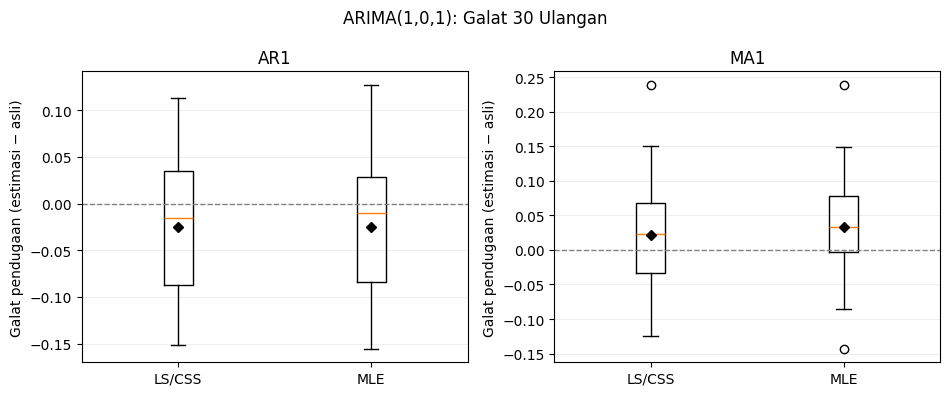

**Interpretasi boxplot:**

**AR1:** median galat LS/CSS -0.0151 dan MLE -0.0104. Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. Pada 30 ulangan ini, ragam penduga lebih kecil untuk **MLE**.

**MA1:** median galat LS/CSS +0.0237 dan MLE +0.0335. Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. Pada 30 ulangan ini, ragam penduga lebih kecil untuk **MLE**.

Garis putus-putus menunjukkan galat nol, garis dalam kotak menunjukkan median, dan simbol belah ketupat hitam menunjukkan **rata-rata galat (bias)**. Whisker dan titik di luar kotak menggambarkan sebaran serta pencilan. Boxplot bukan boxplot dari nilai ragam tunggal; ragam setiap penduga dihitung dari 30 hasil estimasi dan ditampilkan dalam tabel.

In [11]:
ringkas_101 = tampilkan_hasil_ulangan("ARIMA(1,0,1)", hasil_30_101)
plot_boxplot_galat("ARIMA(1,0,1)", hasil_30_101, ringkas_101)


### B. Hasil 30 Ulangan ARIMA(1,1,2)

Setiap ulangan membangkitkan ARIMA(1,1,2) dengan $\phi_1=0.55$, $\theta_1=-0.30$, $\theta_2=0.20$, dan $n=150$. Komponen AR setelah pembedaan memenuhi syarat stasioneritas dan komponen MA memenuhi syarat invertibilitas. **Level deret tidak stasioner karena $d=1$**, tetapi hal itu memang sifat model yang ditugaskan.

Perbandingan tetap hanya antara **LS/CSS dan MLE pada ARIMA(1,1,2)**.


#### ARIMA(1,1,2)

Jumlah ulangan pada setiap parameter: {'AR1': 30, 'MA1': 30, 'MA2': 30}


**Cuplikan pendugaan pada 5 ulangan pertama:**

,Ulangan,Parameter,Parameter asli,LS/CSS,MLE
0,1,AR1,0.5500,0.5897,0.5826
1,1,MA1,-0.3000,-0.4061,-0.4064
2,1,MA2,0.2000,0.2300,0.2311
3,2,AR1,0.5500,0.7556,0.7603
4,2,MA1,-0.3000,-0.6252,-0.6310
5,2,MA2,0.2000,0.1656,0.1643
6,3,AR1,0.5500,0.4469,0.4422
7,3,MA1,-0.3000,-0.0341,-0.0309
8,3,MA2,0.2000,0.2371,0.2425
9,4,AR1,0.5500,0.3086,0.3314


**Bias dan ragam dari 30 ulangan:**

,Parameter,Metode,Parameter asli,Rata-rata penduga,Bias,Ragam penduga
0,AR1,LS/CSS,0.5500,0.5300,-0.0200,0.04053
1,AR1,MLE,0.5500,0.5514,+0.0014,0.04077
2,MA1,LS/CSS,-0.3000,-0.2878,+0.0122,0.03546
3,MA1,MLE,-0.3000,-0.3093,-0.0093,0.04455
4,MA2,LS/CSS,0.2000,0.2028,+0.0028,0.01275
5,MA2,MLE,0.2000,0.1965,-0.0035,0.01551


**Interpretasi tabel:**

**AR1** (asli 0.55): rata-rata penduga LS/CSS 0.5300 dan MLE 0.5514. Biasnya masing-masing -0.0200 dan +0.0014; ragamnya 0.04053 dan 0.04077. Untuk parameter ini, besar bias mutlak lebih kecil pada **MLE**, sedangkan ragam lebih kecil pada **LS/CSS**.

**MA1** (asli -0.30): rata-rata penduga LS/CSS -0.2878 dan MLE -0.3093. Biasnya masing-masing +0.0122 dan -0.0093; ragamnya 0.03546 dan 0.04455. Untuk parameter ini, besar bias mutlak lebih kecil pada **MLE**, sedangkan ragam lebih kecil pada **LS/CSS**.

**MA2** (asli 0.20): rata-rata penduga LS/CSS 0.2028 dan MLE 0.1965. Biasnya masing-masing +0.0028 dan -0.0035; ragamnya 0.01275 dan 0.01551. Untuk parameter ini, besar bias mutlak lebih kecil pada **LS/CSS**, sedangkan ragam lebih kecil pada **LS/CSS**.

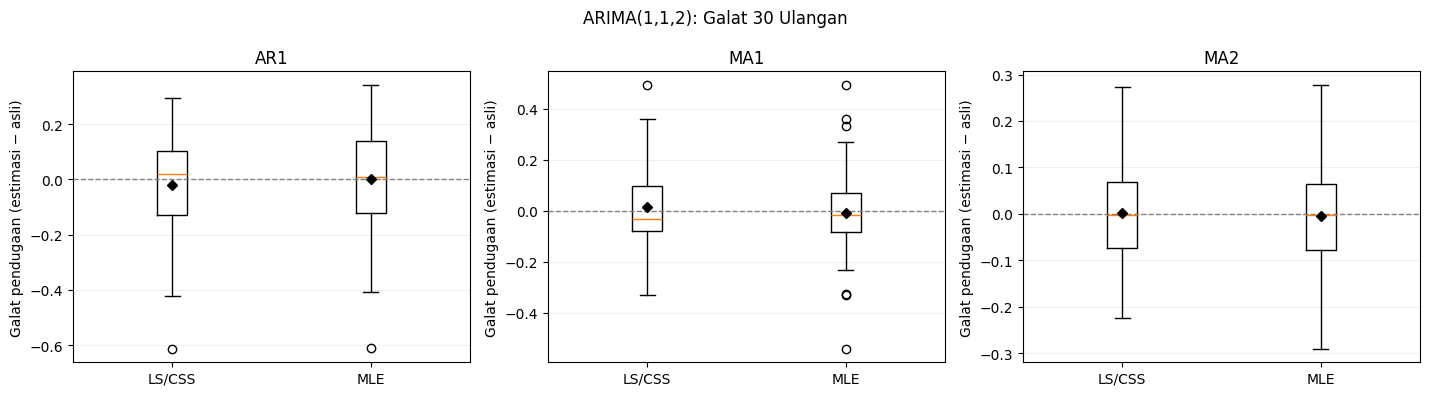

**Interpretasi boxplot:**

**AR1:** median galat LS/CSS +0.0186 dan MLE +0.0105. Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. Pada 30 ulangan ini, ragam penduga lebih kecil untuk **LS/CSS**.

**MA1:** median galat LS/CSS -0.0336 dan MLE -0.0187. Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. Pada 30 ulangan ini, ragam penduga lebih kecil untuk **LS/CSS**.

**MA2:** median galat LS/CSS -0.0014 dan MLE -0.0015. Kotak yang mendekati garis nol menunjukkan galat pendugaan yang cenderung kecil, sedangkan variasi antarsampel dinilai menggunakan sebaran kotak dan ragam tabel. Pada 30 ulangan ini, ragam penduga lebih kecil untuk **LS/CSS**.

Garis putus-putus menunjukkan galat nol, garis dalam kotak menunjukkan median, dan simbol belah ketupat hitam menunjukkan **rata-rata galat (bias)**. Whisker dan titik di luar kotak menggambarkan sebaran serta pencilan. Boxplot bukan boxplot dari nilai ragam tunggal; ragam setiap penduga dihitung dari 30 hasil estimasi dan ditampilkan dalam tabel.

In [12]:
ringkas_112 = tampilkan_hasil_ulangan("ARIMA(1,1,2)", hasil_30_112)
plot_boxplot_galat("ARIMA(1,1,2)", hasil_30_112, ringkas_112)


## Kesimpulan Nomor 2

Berdasarkan **30 realisasi independen per model** dengan parameter asli dan ukuran sampel tetap, perbandingan metode dilakukan berdasarkan **bias** (apakah penduga rata-rata mendekati nilai sebenarnya) dan **ragam** (seberapa berubah penduga pada sampel berbeda). Tabel dan boxplot di atas menjelaskan hasil **untuk setiap parameter secara terpisah**, bukan untuk membandingkan ARIMA(1,0,1) versus ARIMA(1,1,2).

Jika satu metode memiliki bias mutlak lebih kecil tetapi ragam lebih besar, tidak dapat dikatakan bahwa metode tersebut unggul di seluruh kriteria. Hal penting dari pengulangan ini adalah melihat **konsistensi hasil pendugaan** ketika data simulasi berubah, sementara model pembangkit, parameter asli, dan ukuran sampel tidak berubah.


